# 02 — Preprocessing toàn dataset và xử lý timestamp conflicts [NB02-VOTE-V3]

Xử lý mọi user/trajectory, không lấy mẫu. Chọn cụm gần nhau đông nhất trong nhóm cùng timestamp;
nếu hòa, so với các điểm trước/sau trong cùng trajectory. Giữ riêng khi vẫn chưa phân biệt được.

Ngưỡng đã chọn: **20m**. Phần 1–4 scan/phân tích spread; phần 5 đặt ngưỡng;
phần 6 định nghĩa rule; phần 7 trở đi chạy preprocessing/audit/charts.
Đặt ngưỡng None nếu chỉ muốn xem scan trước.

Lần chạy người dùng đã hoàn tất toàn bộ 182 users / 18.670 trajectories với policy spatial_vote_context_v2.
Kết quả tổng hợp ở reports/cp1/results.md. Không chạy lại dataset trong lượt chuẩn bị Git này.


## 1. Dataset và cấu hình

Dataset nằm trong project. Không cần biến môi trường, không chọn danh sách user mẫu.

In [ ]:
from pathlib import Path
from collections import Counter
import gzip
import hashlib
import json
import sys
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from geolife_inference.config import load_config
from geolife_inference.data import GeoLifeSource, POINT_COLUMNS
from geolife_inference.geo import haversine_m
# Voting is visible below; this core bridge only diagnoses the already-resolved rows.
from geolife_inference.preprocessing import diagnose_resolved_points as preprocess

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'src' / 'geolife_inference').is_dir())
assert Path(sys.prefix).resolve() == (ROOT / '.venv').resolve(), 'Chọn kernel Python (GeoLife) / .venv.'
DATASET = ROOT / 'data' / 'Geolife Trajectories 1.3'
assert DATASET.is_dir(), f'Không tìm thấy dataset: {DATASET}'
OUT = ROOT / 'artifacts' / 'preprocessing'
OUT.mkdir(parents=True, exist_ok=True)
config = load_config(ROOT / 'configs' / 'baseline.toml')
source = GeoLifeSource(DATASET)
USERS = sorted(source.by_user)
EXPECTED_USERS = len(USERS)
EXPECTED_TRAJECTORIES = len(source.names)
SCAN_VERSION = 'pairwise-diameter-v1'
POLICY = 'spatial_vote_context_v2'
assert EXPECTED_USERS > 0 and EXPECTED_TRAJECTORIES > 0
get_ipython().run_line_magic('matplotlib', 'inline')
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
display(pd.Series({'Scope': 'ALL users / ALL trajectories / NO point sampling',
                   'Users': EXPECTED_USERS, 'Trajectory files': EXPECTED_TRAJECTORIES}))

Scope               ALL users / ALL trajectories / NO point sampling
Users                                                            182
Trajectory files                                               18670
dtype: object

## 2. Rules và cách đo khoảng lệch

- Loại invalid coordinates/timestamp; giữ missing altitude nếu lat/lon/time hợp lệ.
- Exact duplicate key: user/trajectory/timestamp/lat/lon; chỉ giữ một record, không để duplicates làm tăng phiếu.
- Conflict spread là khoảng cách Haversine lớn nhất giữa mọi pair trong nhóm.
- Nhóm trong ngưỡng được mean-merge. Nhóm vượt ngưỡng được so các cụm có mọi pair nằm trong ngưỡng.
- Chọn cụm đông nhất; nếu hòa, dùng các timestamp không-conflict trước/sau trong ±max_gap_minutes.
- Mỗi context point chỉ bỏ phiếu cho cụm gần nhất trong ngưỡng; vẫn hòa thì giữ riêng cả nhóm.
- Các điểm ngoài cụm thắng được giữ trong file conflict_points.csv, không đưa vào cleaned output.
- Giữ long gaps/high-speed pairs và gắn cờ; timestamp hoàn toàn chưa giải quyết làm ngắt observation segment.

Đây là heuristic ưu tiên, không phải ground truth. Longitude xử lý vòng ±180° trước khi mean.
Điểm gộp có source_point_count và ID đại diện để truy lại.


In [ ]:
KEYS = ['user_id', 'trajectory_id', 'timestamp', 'latitude', 'longitude']
TIME_KEYS = ['user_id', 'trajectory_id', 'timestamp']


def dataset_fingerprint():
    current = GeoLifeSource(DATASET)
    assert current.names == source.names, 'Danh sách PLT đã đổi; khởi động lại notebook để lấy đủ phạm vi.'
    metadata = [(name, (DATASET / name).stat().st_size, (DATASET / name).stat().st_mtime_ns)
                for name in current.names]
    return hashlib.sha256(json.dumps(metadata).encode('utf-8')).hexdigest()


def write_json_atomic(path, value):
    temporary = path.with_name(path.name + '.partial')
    temporary.write_text(json.dumps(value, ensure_ascii=False, indent=2, allow_nan=False), encoding='utf-8')
    temporary.replace(path)


def split_basic(raw):
    bad_coordinate = (~np.isfinite(raw.latitude) | ~np.isfinite(raw.longitude)
                      | ~raw.latitude.between(-90, 90) | ~raw.longitude.between(-180, 180))
    bad_timestamp = raw.timestamp.isna()
    valid = ~(bad_coordinate | bad_timestamp)
    duplicate = pd.Series(False, index=raw.index)
    duplicate.loc[valid] = raw.loc[valid].duplicated(KEYS, keep='first')
    distinct = raw.loc[valid & ~duplicate].copy()
    return distinct, bad_coordinate, bad_timestamp, duplicate


def conflict_groups(distinct):
    mask = distinct.duplicated(TIME_KEYS, keep=False)
    return distinct.loc[mask].groupby('timestamp', sort=True)


def group_id(group):
    row = group.iloc[0]
    return f"{row.user_id}/{row.trajectory_id}@{row.timestamp.isoformat()}"


def group_diameter_m(group):
    coords = group[['latitude', 'longitude']].to_numpy(dtype=float)
    maximum = 0.0
    # Mọi pair trong nhóm; không tạo ma trận N x N trong RAM.
    for i in range(len(coords) - 1):
        distances = haversine_m(coords[i, 0], coords[i, 1], coords[i+1:, 0], coords[i+1:, 1])
        maximum = max(maximum, float(np.max(distances)))
    return maximum


def mean_coordinate(group):
    base = float(group.longitude.iloc[0])
    unwrapped = base + ((group.longitude.to_numpy() - base + 180) % 360 - 180)
    latitude = float(group.latitude.mean())
    longitude = float((unwrapped.mean() + 180) % 360 - 180)
    return latitude, longitude

## 3. Quét mọi timestamp conflict

Quét tất cả PLT để tính độ lệch; không chạy cleaning/gộp ở bước này.
Cache chỉ được dùng khi đã quét đủ users/files và metadata dataset không đổi.
Fingerprint dùng tên, size, mtime, không phải checksum nội dung từng file.

In [ ]:
SCAN_COLUMNS = ['group_id', 'user_id', 'trajectory_id', 'timestamp', 'distinct_positions', 'spread_m']
scan_csv = OUT / 'conflict_groups.csv'
scan_json = OUT / 'conflict_scan.json'
fingerprint = dataset_fingerprint()
old_scan = json.loads(scan_json.read_text(encoding='utf-8')) if scan_json.exists() else {}
cache_valid = (scan_csv.exists() and old_scan.get('status') == 'completed'
               and old_scan.get('scan_version') == SCAN_VERSION
               and old_scan.get('dataset_fingerprint') == fingerprint
               and old_scan.get('completed_user_count') == EXPECTED_USERS
               and old_scan.get('processed_trajectory_files') == EXPECTED_TRAJECTORIES)

if cache_valid:
    scan_report = old_scan
    print('Dùng kết quả quét toàn dataset đã khớp metadata.')
else:
    scan_report = {'scope': 'full_dataset', 'status': 'running', 'scan_version': SCAN_VERSION,
        'dataset_fingerprint': fingerprint, 'expected_user_count': EXPECTED_USERS,
        'expected_trajectory_files': EXPECTED_TRAJECTORIES, 'completed_user_count': 0,
        'processed_trajectory_files': 0, 'input_rows': 0, 'conflict_group_count': 0}
    temporary = scan_csv.with_name(scan_csv.name + '.partial')
    try:
        write_json_atomic(scan_json, scan_report)
        with temporary.open('w', encoding='utf-8', newline='') as stream:
            pd.DataFrame(columns=SCAN_COLUMNS).to_csv(stream, index=False)
            for user in USERS:
                for name, raw in zip(source.by_user[user], source.trajectories(user), strict=True):
                    scan_report['input_rows'] += len(raw)
                    if not raw.empty:
                        distinct, *_ = split_basic(raw)
                        rows = []
                        for timestamp, group in conflict_groups(distinct):
                            rows.append({'group_id': group_id(group), 'user_id': user,
                                'trajectory_id': str(group.trajectory_id.iloc[0]),
                                'timestamp': timestamp.isoformat(), 'distinct_positions': len(group),
                                'spread_m': group_diameter_m(group)})
                        if rows:
                            pd.DataFrame(rows, columns=SCAN_COLUMNS).to_csv(stream, index=False, header=False)
                        scan_report['conflict_group_count'] += len(rows)
                    scan_report['processed_trajectory_files'] += 1
                scan_report['completed_user_count'] += 1
                write_json_atomic(scan_json, scan_report)
                print(f"[scan {scan_report['completed_user_count']}/{EXPECTED_USERS}] user {user}", flush=True)
        assert scan_report['processed_trajectory_files'] == EXPECTED_TRAJECTORIES
        assert scan_report['completed_user_count'] == EXPECTED_USERS
        assert dataset_fingerprint() == fingerprint, 'Dataset thay đổi trong lúc scan; cần quét lại.'
        temporary.replace(scan_csv)
        scan_report['status'] = 'completed'
        write_json_atomic(scan_json, scan_report)
    except Exception as error:
        scan_report.update(status='failed', error=str(error))
        write_json_atomic(scan_json, scan_report)
        raise

conflicts = pd.read_csv(scan_csv, dtype={'group_id': str, 'user_id': str, 'trajectory_id': str, 'timestamp': str})
assert len(conflicts) == scan_report['conflict_group_count']
assert conflicts.group_id.is_unique
display(pd.Series({'Users scanned': scan_report['completed_user_count'],
                   'Trajectories scanned': scan_report['processed_trajectory_files'],
                   'Input rows scanned': scan_report['input_rows'],
                   'Conflict groups': len(conflicts)}, name='Toàn dataset'))

[scan 1/182] user 000
[scan 2/182] user 001
[scan 3/182] user 002
[scan 4/182] user 003
[scan 5/182] user 004
[scan 6/182] user 005
[scan 7/182] user 006
[scan 8/182] user 007
[scan 9/182] user 008
[scan 10/182] user 009
[scan 11/182] user 010
[scan 12/182] user 011
[scan 13/182] user 012
[scan 14/182] user 013
[scan 15/182] user 014
[scan 16/182] user 015
[scan 17/182] user 016
[scan 18/182] user 017
[scan 19/182] user 018
[scan 20/182] user 019
[scan 21/182] user 020
[scan 22/182] user 021
[scan 23/182] user 022
[scan 24/182] user 023
[scan 25/182] user 024
[scan 26/182] user 025
[scan 27/182] user 026
[scan 28/182] user 027
[scan 29/182] user 028
[scan 30/182] user 029
[scan 31/182] user 030
[scan 32/182] user 031
[scan 33/182] user 032
[scan 34/182] user 033
[scan 35/182] user 034
[scan 36/182] user 035
[scan 37/182] user 036
[scan 38/182] user 037
[scan 39/182] user 038
[scan 40/182] user 039
[scan 41/182] user 040
[scan 42/182] user 041
[scan 43/182] user 042
[scan 44/182] user 0

Users scanned                182
Trajectories scanned       18670
Input rows scanned      24876978
Conflict groups           157865
Name: Toàn dataset, dtype: int64

## 4. Phân phối khoảng lệch trên toàn dataset

Mỗi nhóm conflict đóng góp một giá trị spread. Bảng percentile và biểu đồ dùng mọi nhóm, không lấy mẫu.
Chart log chỉ vẽ spread >0; số nhóm spread=0 được báo riêng.

count    157865.000000
mean        258.735361
std       13808.979882
min           0.085276
25%           0.624328
50%           1.365438
75%           3.453434
90%           7.534374
95%          10.379181
99%          14.152726
max      852278.886837
Name: Spread meters, dtype: float64

Groups with zero spread: 0


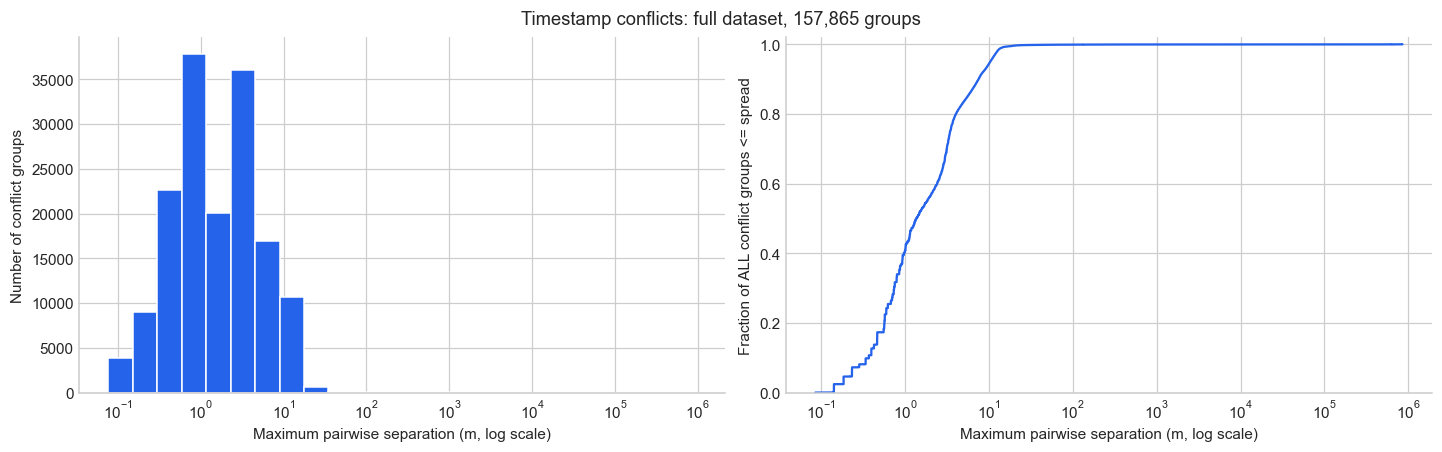

In [ ]:
if conflicts.empty:
    print('Không có timestamp conflict trên toàn dataset.')
else:
    display(conflicts.spread_m.describe(percentiles=[.25, .5, .75, .9, .95, .99]).rename('Spread meters'))
    print(f'Groups with zero spread: {int(conflicts.spread_m.eq(0).sum()):,}')
    positive = conflicts.loc[conflicts.spread_m > 0, 'spread_m']
    fig, axes = plt.subplots(1, 2, figsize=(13, 4), constrained_layout=True)
    if not positive.empty:
        bins = np.geomspace(max(1e-12, positive.min() * .9), positive.max() * 1.1, 25)
        axes[0].hist(positive, bins=bins, color='#2563eb', edgecolor='white')
        axes[0].set_xscale('log')
        counts = conflicts.spread_m.value_counts().sort_index()
        cumulative = counts.cumsum() / counts.sum()
        mask = counts.index > 0
        axes[1].step(counts.index[mask], cumulative.loc[mask], where='post', color='#2563eb')
        axes[1].set_xscale('log')
    axes[0].set_xlabel('Maximum pairwise separation (m, log scale)')
    axes[0].set_ylabel('Number of conflict groups')
    axes[1].set_xlabel('Maximum pairwise separation (m, log scale)')
    axes[1].set_ylabel('Fraction of ALL conflict groups <= spread')
    axes[1].set_ylim(0, 1.02)
    fig.suptitle(f'Timestamp conflicts: full dataset, {len(conflicts):,} groups')
    fig.savefig(OUT / '03_conflict_spread.png', dpi=140, bbox_inches='tight')
    plt.show()

## 5. Ngưỡng gộp

Sau khi xem phần 4, thay `None` dưới đây bằng ngưỡng meters có cơ sở từ phân phối và yêu cầu bài toán.
Không tự dùng một percentile làm ngưỡng đúng. Sau khi đổi ngưỡng, chạy lại từ cell này trở đi.
Nếu chưa đặt, các cell sau bỏ qua cleaning và không ghi đè cleaned CSV/audit cũ.

In [ ]:
CONFLICT_MERGE_THRESHOLD_M = 20  # Đặt ngưỡng meters sau khi xem phân phối toàn dataset.
report = None
if conflicts.empty:
    MERGE_THRESHOLD_M = 0.0  # Không có nhóm cần quyết định.
    READY_TO_CLEAN = True
elif CONFLICT_MERGE_THRESHOLD_M is None:
    MERGE_THRESHOLD_M = None
    READY_TO_CLEAN = False
    display(Markdown('**Đã có thống kê conflict; chưa gộp.** Đặt ngưỡng ở cell này rồi chạy lại phần 5 trở đi.'))
else:
    value = CONFLICT_MERGE_THRESHOLD_M
    if isinstance(value, bool) or not isinstance(value, (int, float)) or not np.isfinite(value) or value < 0:
        raise ValueError('Ngưỡng phải là số meters hữu hạn, không âm.')
    MERGE_THRESHOLD_M = float(value)
    READY_TO_CLEAN = True
    near = conflicts.spread_m <= MERGE_THRESHOLD_M
    display(pd.Series({'Threshold (m)': MERGE_THRESHOLD_M, 'Groups to mean-merge': int(near.sum()),
                       'Groups needing spatial/context voting': int((~near).sum())}, name='Phạm vi quyết định'))
conflict_lookup = conflicts.set_index('group_id')[['spread_m', 'distinct_positions']].to_dict('index')

Threshold (m)               20.0
Groups to mean-merge    157253.0
Groups to quarantine       612.0
Name: Phạm vi quyết định, dtype: float64

## 6. Xử lý từng trajectory và giải quyết timestamp conflict

Phần này làm sạch từng file trajectory theo thứ tự:

Loại điểm không hợp lệ và bản ghi trùng.

Xử lý các điểm cùng timestamp:

Nếu các điểm đều gần nhau trong ngưỡng bước 5 → gộp bằng tọa độ trung bình.

Nếu có điểm lệch xa → tìm cụm có nhiều điểm gần nhau nhất và ưu tiên cụm đó.

Nếu các cụm đông bằng nhau → so sánh thêm với các điểm trước/sau trong cùng trajectory, mặc định trong khoảng ±5 phút. Chỉ dùng các timestamp không có conflict.

Mỗi điểm trước/sau bỏ phiếu cho một cụm gần nhất nằm trong ngưỡng. Nếu vẫn hòa hoặc không có bằng chứng hỗ trợ → giữ riêng cả nhóm để xem xét.

Lưu kết quả: cụm được chọn tạo thành một điểm trung bình; các điểm không được chọn vẫn được lưu trong conflict_points.csv.

Tính gap và tốc độ, gắn cờ bất thường. Timestamp chưa giải quyết được sẽ làm ngắt đoạn quan sát.

In [ ]:
POLICY = "spatial_vote_context_v2"


def positive_frequencies(gaps):
    return {
        float(seconds): int(count)
        for seconds, count in gaps[gaps > 0].value_counts().items()
    }


def before_diagnostics(raw):
    if raw.empty:
        return pd.Series(dtype=float), 0

    gaps = raw.timestamp.diff().dt.total_seconds()
    previous_lat = raw.latitude.shift(1)
    previous_lon = raw.longitude.shift(1)
    valid = (
        raw.latitude.between(-90, 90)
        & raw.longitude.between(-180, 180)
        & previous_lat.between(-90, 90)
        & previous_lon.between(-180, 180)
    )
    distances = pd.Series(np.nan, index=raw.index)
    distances.loc[valid] = haversine_m(
        raw.loc[valid, "latitude"].to_numpy(),
        raw.loc[valid, "longitude"].to_numpy(),
        previous_lat.loc[valid].to_numpy(),
        previous_lon.loc[valid].to_numpy(),
    )
    speeds = distances / gaps.where(gaps > 0)
    return gaps, int(speeds.gt(config.speed_warning_mps).sum())


def choose_conflict_points(group, distinct, threshold_m):
    coords = group[["latitude", "longitude"]].to_numpy()
    distances = haversine_m(
        coords[:, 0, None], coords[:, 1, None],
        coords[None, :, 0], coords[None, :, 1],
    )

    # Tìm các nhóm đông nhất mà mọi cặp điểm đều trong ngưỡng.
    # Giữ tất cả phương án hòa, không chọn theo thứ tự điểm.
    from itertools import combinations

    close = distances <= threshold_m
    upper_bound = int(close.sum(axis=1).max())
    for size in range(upper_bound, 0, -1):
        leaders = [
            list(indices)
            for indices in combinations(range(len(group)), size)
            if close[np.ix_(indices, indices)].all()
        ]
        if leaders:
            break

    if len(leaders) == 1:
        return group.iloc[leaders[0]], "spatial_vote"

    # Nếu hòa, dùng các điểm trước/sau trong cùng trajectory.
    timestamp = group.timestamp.iloc[0]
    window = pd.Timedelta(minutes=config.max_gap_minutes)
    context = distinct.loc[
        distinct.timestamp.ne(timestamp)
        & (distinct.timestamp - timestamp).abs().le(window)
        & ~distinct.duplicated(TIME_KEYS, keep=False)
    ]
    if context.empty:
        return None, "unresolved_tie"

    centers = [mean_coordinate(group.iloc[c]) for c in leaders]
    d = np.column_stack([
        haversine_m(
            context.latitude.to_numpy(),
            context.longitude.to_numpy(),
            latitude, longitude,
        )
        for latitude, longitude in centers
    ])
    nearest = d.argmin(axis=1)
    minimum = d.min(axis=1)
    unique_nearest = np.isclose(
        d, minimum[:, None], atol=1e-6, rtol=0
    ).sum(axis=1) == 1

    # Mỗi điểm context chỉ bỏ phiếu cho một cụm gần nhất trong ngưỡng.
    eligible = unique_nearest & (minimum <= threshold_m)
    votes = np.bincount(nearest[eligible], minlength=len(leaders))
    winners = np.flatnonzero(votes == votes.max())

    if votes.max() == 0 or len(winners) != 1:
        return None, "unresolved_tie"
    return group.iloc[leaders[int(winners[0])]], "context_vote"


def clean_trajectory(raw, threshold_m, lookup):
    if (
        threshold_m is None
        or isinstance(threshold_m, bool)
        or not np.isfinite(threshold_m)
        or threshold_m < 0
    ):
        raise ValueError("Ngưỡng conflict phải hữu hạn và không âm.")

    names = [
        "input_points", "invalid_coordinates", "invalid_timestamps",
        "invalid_rows_removed", "invalid_altitudes",
        "duplicate_records_removed", "conflict_groups", "conflict_positions",
        "merged_conflict_groups", "merged_source_points", "merged_extra_points",
        "unresolved_conflict_groups", "unresolved_conflict_rows",
        "resolved_conflict_groups", "context_resolved_groups",
        "outlier_conflict_rows", "output_points", "missing_altitude_after",
        "gaps_over_limit", "high_speed_segments", "breaks_due_to_conflict",
    ]
    stats = dict.fromkeys(names, 0)
    stats["input_points"] = len(raw)
    stats["invalid_altitudes"] = int(
        (~np.isfinite(pd.to_numeric(raw.altitude_m, errors="coerce"))).sum()
    )

    if raw.empty:
        distinct = raw.copy()
        removed = raw.copy()
        removed["reason"] = pd.Series(dtype=str)
    else:
        distinct, bad_coordinate, bad_timestamp, duplicate = split_basic(raw)
        stats.update(
            invalid_coordinates=int(bad_coordinate.sum()),
            invalid_timestamps=int(bad_timestamp.sum()),
            invalid_rows_removed=int((bad_coordinate | bad_timestamp).sum()),
            duplicate_records_removed=int(duplicate.sum()),
        )
        reasons = pd.Series(
            np.select(
                [
                    bad_coordinate & bad_timestamp,
                    bad_coordinate, bad_timestamp, duplicate,
                ],
                [
                    "invalid_coordinate_and_timestamp",
                    "invalid_coordinate", "invalid_timestamp", "duplicate_point",
                ],
                default="",
            ),
            index=raw.index,
        )
        removed = raw.loc[reasons.ne("")].copy()
        removed["reason"] = reasons.loc[removed.index]

    ordinary = distinct.loc[
        ~distinct.duplicated(TIME_KEYS, keep=False)
    ].copy()
    ordinary["coordinate_merged"] = False
    ordinary["source_point_count"] = 1
    pieces, traces, unresolved_times = [ordinary], [], []

    for timestamp, group in conflict_groups(distinct):
        measured = lookup[group_id(group)]
        assert int(measured["distinct_positions"]) == len(group)
        spread = float(measured["spread_m"])
        stats["conflict_groups"] += 1
        stats["conflict_positions"] += len(group)

        if spread <= threshold_m:
            selected, method = group, "spatial_vote"
        else:
            selected, method = choose_conflict_points(
                group, distinct, threshold_m
            )

        trace = group.copy()
        trace["conflict_group_id"] = group_id(group)
        trace["spread_m"] = spread
        trace["output_record_id"] = pd.NA

        if selected is None:
            trace["decision"] = "unresolved_tie"
            unresolved_times.append(timestamp.value)
            stats["unresolved_conflict_groups"] += 1
            stats["unresolved_conflict_rows"] += len(group)
        else:
            n = len(selected)
            output = selected.loc[[selected.record_id.idxmin()]].copy()
            output["latitude"], output["longitude"] = mean_coordinate(selected)
            output["altitude_m"] = selected.altitude_m.where(
                np.isfinite(selected.altitude_m)
            ).mean()
            output["coordinate_merged"] = n > 1
            output["source_point_count"] = n
            pieces.append(output)

            accepted = trace.record_id.isin(selected.record_id)
            trace["decision"] = "rejected_by_vote"
            trace.loc[accepted, "decision"] = (
                "mean_merged" if n > 1 else "selected_by_context"
            )
            trace.loc[accepted, "output_record_id"] = int(
                output.record_id.iloc[0]
            )
            stats["resolved_conflict_groups"] += 1
            stats["context_resolved_groups"] += int(method == "context_vote")
            stats["merged_conflict_groups"] += int(n > 1)
            stats["merged_source_points"] += n if n > 1 else 0
            stats["merged_extra_points"] += n - 1
            stats["outlier_conflict_rows"] += len(group) - n

            # Giữ tên counter cũ để các bước 7–8 tiếp tục chạy được.
            # Đây là mọi conflict rows bị tách khỏi cleaned output.
            stats["unresolved_conflict_rows"] += len(group) - n

        traces.append(trace)

    ready = pd.concat(pieces, ignore_index=True)
    trace_columns = [
        *POINT_COLUMNS, "record_id", "conflict_group_id",
        "spread_m", "decision", "output_record_id",
    ]
    provenance = (
        pd.concat(traces, ignore_index=True)
        if traces else pd.DataFrame(columns=trace_columns)
    )
    cleaned, core = preprocess(ready, config)
    assert (
        core["invalid_rows_removed"]
        == core["duplicate_records_removed"]
        == core["conflicting_timestamps_removed"]
        == 0
    )

    cleaned["gap_over_limit"] = (
        cleaned.gap_seconds > config.max_gap_minutes * 60
    )
    cleaned["high_speed_flag"] = (
        cleaned.speed_mps > config.speed_warning_mps
    )
    breaks = np.zeros(len(cleaned), dtype=bool)
    if len(cleaned) and unresolved_times:
        counts = np.searchsorted(
            np.sort(np.asarray(unresolved_times, dtype=np.int64)),
            cleaned.timestamp.astype("int64").to_numpy(),
        )
        breaks = np.diff(counts, prepend=counts[0]) > 0
    cleaned["segment_break_due_to_conflict"] = breaks
    starts = (
        cleaned.gap_seconds.isna()
        | cleaned.gap_over_limit
        | cleaned.gap_seconds.le(0)
        | cleaned.segment_break_due_to_conflict
    )
    cleaned["observation_segment"] = starts.cumsum().astype(int)
    stats.update(
        output_points=len(cleaned),
        missing_altitude_after=int(cleaned.altitude_m.isna().sum()),
        gaps_over_limit=core["gaps_over_limit"],
        high_speed_segments=core["high_speed_segments"],
        breaks_due_to_conflict=int(breaks.sum()),
    )

    assert len(raw) == (
        len(cleaned) + len(removed)
        + stats["merged_extra_points"] + stats["unresolved_conflict_rows"]
    )
    assert (
        int(cleaned.source_point_count.sum())
        + len(removed) + stats["unresolved_conflict_rows"] == len(raw)
    )
    assert len(provenance) == stats["conflict_positions"]
    assert cleaned.record_id.is_unique
    assert not cleaned.duplicated(TIME_KEYS).any()
    return cleaned, removed, provenance, stats


## 7. Preprocessing mọi user sau khi chọn ngưỡng

Không chọn subset. CSV nén được ghi theo luồng. `audit.json` chỉ báo completed khi đủ mọi users/files,
counts bảo toàn và scope/threshold/fingerprint khớp. Lỗi làm dừng cả lần chạy, không âm thầm bỏ file.
Output `.partial` chỉ thay kết quả chính khi xử lý xong toàn bộ.

In [23]:
CLEAN_COLUMNS = [*POINT_COLUMNS, 'record_id', 'coordinate_merged', 'source_point_count',
    'gap_seconds', 'distance_m', 'speed_mps', 'gap_over_limit', 'high_speed_flag',
    'segment_break_due_to_conflict', 'observation_segment']
REMOVED_COLUMNS = [*POINT_COLUMNS, 'record_id', 'reason']
TRACE_COLUMNS = [*POINT_COLUMNS, 'record_id', 'conflict_group_id', 'spread_m', 'decision', 'output_record_id']

if not READY_TO_CLEAN:
    display(Markdown('**Chưa chạy cleaning:** đặt ngưỡng tại phần 5. Các CSV/audit cleaning cũ được giữ nguyên.'))
else:
    assert dataset_fingerprint() == fingerprint, 'Dataset đã đổi; chạy lại phần scan.'
    started = time.perf_counter()
    per_user, before_frequency, after_frequency = [], Counter(), Counter()
    record_offset = 0
    clean_partial, removed_partial = OUT / 'cleaned_points.csv.gz.partial', OUT / 'removed_points.csv.partial'
    trace_partial = OUT / 'conflict_points.csv.partial'

    def save_audit(status, error=None, with_frequencies=False):
        fields = sorted({key for row in per_user for key in row if key not in ['user_id', 'before_utc_dates', 'after_utc_dates']})
        totals = {key: int(sum(row.get(key, 0) for row in per_user)) for key in fields}
        document = {'scope': 'full_dataset', 'status': status, 'conflict_policy': POLICY,
            'merge_threshold_m': MERGE_THRESHOLD_M, 'dataset_fingerprint': fingerprint,
            'expected_users': USERS, 'expected_user_count': EXPECTED_USERS,
            'expected_trajectory_files': EXPECTED_TRAJECTORIES, 'completed_user_count': len(per_user),
            'processed_trajectory_files': int(totals.get('trajectory_files', 0)),
            'max_gap_minutes': config.max_gap_minutes, 'speed_warning_mps': config.speed_warning_mps,
            'totals': totals, 'per_user': per_user, 'elapsed_seconds': time.perf_counter() - started}
        if error is not None:
            document['error'] = str(error)
        if with_frequencies:
            document['sampling_frequency'] = [{'seconds': s, 'before_pairs': int(before_frequency[s]),
                'after_pairs': int(after_frequency[s])} for s in sorted(before_frequency.keys() | after_frequency.keys())]
        write_json_atomic(OUT / 'audit.json', document)
        return document

    save_audit('running')
    try:
        with gzip.open(clean_partial, 'wt', encoding='utf-8', newline='', compresslevel=1) as clean_stream, removed_partial.open('w', encoding='utf-8', newline='') as removed_stream, trace_partial.open('w', encoding='utf-8', newline='') as trace_stream:
            for columns, stream in [(CLEAN_COLUMNS, clean_stream), (REMOVED_COLUMNS, removed_stream), (TRACE_COLUMNS, trace_stream)]:
                pd.DataFrame(columns=columns).to_csv(stream, index=False)
            for user in USERS:
                row = Counter()
                before_dates, after_dates = set(), set()
                for name, raw in zip(source.by_user[user], source.trajectories(user), strict=True):
                    raw['record_id'] = np.arange(record_offset, record_offset + len(raw))
                    record_offset += len(raw)
                    gaps, fast_before = before_diagnostics(raw)
                    cleaned, removed, traces, stats = clean_trajectory(raw, MERGE_THRESHOLD_M, conflict_lookup)
                    row.update(stats)
                    row.update({'trajectory_files': 1, 'before_trajectories': int(not raw.empty),
                        'after_trajectories': int(not cleaned.empty), 'zero_time_pairs_before': int(gaps.eq(0).sum()),
                        'positive_pairs_before': int(gaps.gt(0).sum()),
                        'positive_pairs_after': int(cleaned.gap_seconds.gt(0).sum()),
                        'gaps_over_limit_before': int(gaps.gt(config.max_gap_minutes * 60).sum()),
                        'high_speed_pairs_before': fast_before})
                    before_frequency.update(positive_frequencies(gaps))
                    after_frequency.update(positive_frequencies(cleaned.gap_seconds))
                    if not raw.empty:
                        before_dates.update(raw.timestamp.dropna().dt.date.unique())
                    if not cleaned.empty:
                        after_dates.update(cleaned.timestamp.dt.date.unique())
                    cleaned[CLEAN_COLUMNS].to_csv(clean_stream, index=False, header=False)
                    removed[REMOVED_COLUMNS].to_csv(removed_stream, index=False, header=False)
                    traces[TRACE_COLUMNS].to_csv(trace_stream, index=False, header=False)
                record = {'user_id': user, **dict(row), 'before_utc_dates': len(before_dates), 'after_utc_dates': len(after_dates)}
                assert record['trajectory_files'] == len(source.by_user[user])
                per_user.append(record)
                save_audit('running')
                print(f"[clean {len(per_user)}/{EXPECTED_USERS}] user {user}: {row['input_points']:,} -> {row['output_points']:,}", flush=True)
        assert len(per_user) == EXPECTED_USERS
        assert sum(r['trajectory_files'] for r in per_user) == EXPECTED_TRAJECTORIES
        assert record_offset == scan_report['input_rows']
        assert sum(r['conflict_groups'] for r in per_user) == len(conflicts)
        assert sum(r['conflict_positions'] for r in per_user) == int(conflicts.distinct_positions.sum())
        assert sum(before_frequency.values()) == sum(r['positive_pairs_before'] for r in per_user)
        assert sum(after_frequency.values()) == sum(r['positive_pairs_after'] for r in per_user)
        assert dataset_fingerprint() == fingerprint, 'Dataset đổi trong lúc cleaning; output chưa được công bố.'
        clean_partial.replace(OUT / 'cleaned_points.csv.gz')
        removed_partial.replace(OUT / 'removed_points.csv')
        trace_partial.replace(OUT / 'conflict_points.csv')
        report = save_audit('completed', with_frequencies=True)
    except Exception as error:
        save_audit('failed', error=error)
        raise

[clean 1/182] user 000: 173,870 -> 173,870
[clean 2/182] user 001: 108,607 -> 108,607
[clean 3/182] user 002: 248,217 -> 248,214
[clean 4/182] user 003: 485,226 -> 485,226
[clean 5/182] user 004: 439,397 -> 439,397
[clean 6/182] user 005: 109,046 -> 109,046
[clean 7/182] user 006: 31,830 -> 31,830
[clean 8/182] user 007: 87,217 -> 85,531
[clean 9/182] user 008: 77,910 -> 77,908
[clean 10/182] user 009: 84,616 -> 84,614
[clean 11/182] user 010: 935,576 -> 931,663
[clean 12/182] user 011: 90,803 -> 90,793
[clean 13/182] user 012: 147,092 -> 147,087
[clean 14/182] user 013: 291,182 -> 291,172
[clean 15/182] user 014: 388,213 -> 388,212
[clean 16/182] user 015: 87,736 -> 87,734
[clean 17/182] user 016: 89,272 -> 89,269
[clean 18/182] user 017: 1,026,179 -> 1,026,176
[clean 19/182] user 018: 47,279 -> 47,279
[clean 20/182] user 019: 47,824 -> 47,823
[clean 21/182] user 020: 177,681 -> 177,677
[clean 22/182] user 021: 2,385 -> 2,385
[clean 23/182] user 022: 471,437 -> 471,437
[clean 24/182] 

## 8. Audit và charts toàn dataset

Rows absorbed into means đã đóng góp vào điểm trung bình, không phải thông tin bị xóa.
unresolved_conflict_rows là tổng conflict points tách khỏi cleaned output, bao gồm cả outliers ngoài cụm thắng.
outlier_conflict_rows đếm riêng các điểm ngoài cụm thắng; unresolved_conflict_groups đếm nhóm còn hòa.
Mọi điểm tách đều được giữ trong conflict_points.csv.


In [24]:
if report is not None:
    assert report['status'] == 'completed' and report['conflict_policy'] == POLICY
    assert report['completed_user_count'] == EXPECTED_USERS
    assert report['processed_trajectory_files'] == EXPECTED_TRAJECTORIES
    totals = report['totals']
    assert totals['input_points'] == (totals['output_points'] + totals['invalid_rows_removed']
        + totals['duplicate_records_removed'] + totals['merged_extra_points'] + totals['unresolved_conflict_rows'])
    display(pd.Series({
        'Users processed': report['completed_user_count'], 'Trajectory files processed': report['processed_trajectory_files'],
        'Input points': totals['input_points'], 'Cleaned output points': totals['output_points'],
        'Invalid removed': totals['invalid_rows_removed'], 'Duplicate removed': totals['duplicate_records_removed'],
        'Conflict groups mean-merged': totals['merged_conflict_groups'],
        'Extra rows absorbed into means': totals['merged_extra_points'],
        'Conflict points separated for review': totals['unresolved_conflict_rows'],
        'Missing-altitude output rows': totals['missing_altitude_after'],
        'High-speed pairs retained': totals['high_speed_segments'], 'Long gaps retained': totals['gaps_over_limit']}, name='FULL DATASET'))
    audit = pd.DataFrame(report['per_user']).set_index('user_id')
    columns = ['input_points', 'invalid_rows_removed', 'duplicate_records_removed', 'merged_conflict_groups',
               'merged_extra_points', 'unresolved_conflict_rows', 'output_points', 'before_utc_dates', 'after_utc_dates']
    with pd.option_context('display.max_rows', EXPECTED_USERS):
        display(audit[columns])

Users processed                        182
Trajectory files processed           18670
Input points                      24876978
Cleaned output points             24177772
Invalid removed                          1
Duplicate removed                   146914
Conflict groups mean-merged         157453
Extra rows absorbed into means      551156
Far conflict rows quarantined         1135
Missing-altitude output rows         55484
High-speed pairs retained            51686
Long gaps retained                   39806
Name: FULL DATASET, dtype: int64

,input_points,invalid_rows_removed,duplicate_records_removed,merged_conflict_groups,merged_extra_points,unresolved_conflict_rows,output_points,before_utc_dates,after_utc_dates
user_id,,,,,,,,,
000,173870,0,0,0,0,0,173870,125,125
001,108607,0,0,0,0,0,108607,45,45
002,248217,0,0,2,2,1,248214,118,118
003,485226,0,0,0,0,0,485226,239,239
004,439397,0,0,0,0,0,439397,263,263
005,109046,0,0,0,0,0,109046,61,61
006,31830,0,0,0,0,0,31830,25,25
007,87217,0,1686,0,0,0,85531,41,41
008,77910,0,0,1,1,1,77908,31,31


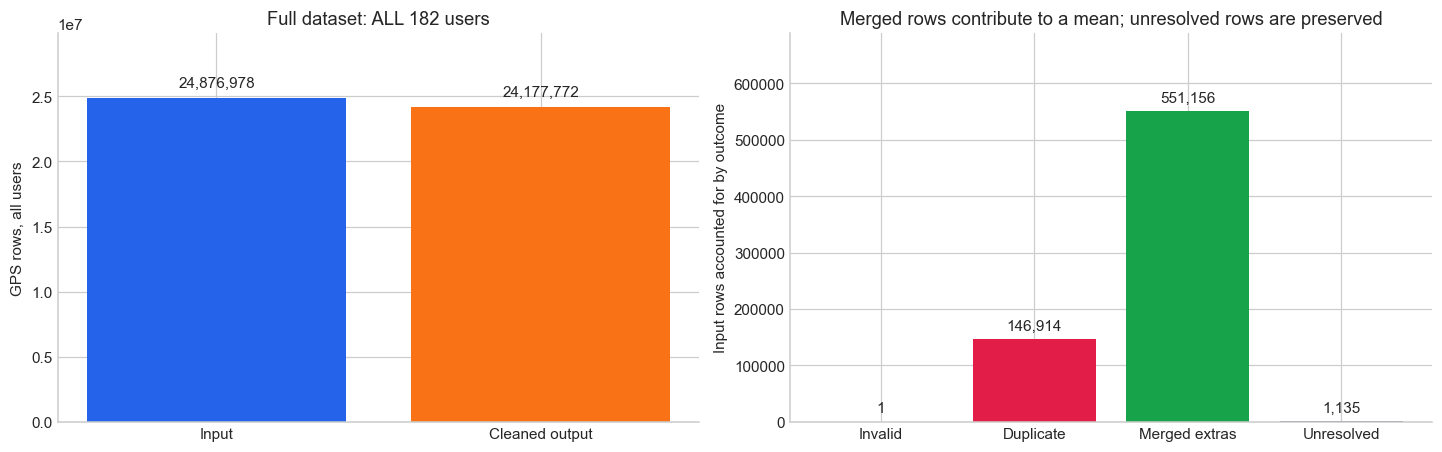

In [25]:
if report is not None:
    fig, axes = plt.subplots(1, 2, figsize=(13, 4), constrained_layout=True)
    bars = axes[0].bar(['Input', 'Cleaned output'], [totals['input_points'], totals['output_points']], color=['#2563eb', '#f97316'])
    axes[0].bar_label(bars, labels=[f'{b.get_height():,.0f}' for b in bars], padding=5)
    axes[0].set_ylim(0, max(1, totals['input_points']) * 1.2)
    axes[0].set_ylabel('GPS rows, all users')
    axes[0].set_title(f'Full dataset: ALL {EXPECTED_USERS} users')
    values = [totals['invalid_rows_removed'], totals['duplicate_records_removed'], totals['merged_extra_points'], totals['unresolved_conflict_rows']]
    bars = axes[1].bar(['Invalid', 'Duplicate', 'Merged extras', 'Unresolved'], values, color=['#e11d48', '#e11d48', '#16a34a', '#64748b'])
    axes[1].bar_label(bars, labels=[f'{v:,}' for v in values], padding=4)
    axes[1].set_ylim(0, max(1, max(values)) * 1.25)
    axes[1].set_ylabel('Input rows accounted for by outcome')
    axes[1].set_title('Merged rows contribute to a mean; unresolved rows are preserved')
    fig.savefig(OUT / '01_record_counts.png', dpi=140, bbox_inches='tight')
    plt.show()

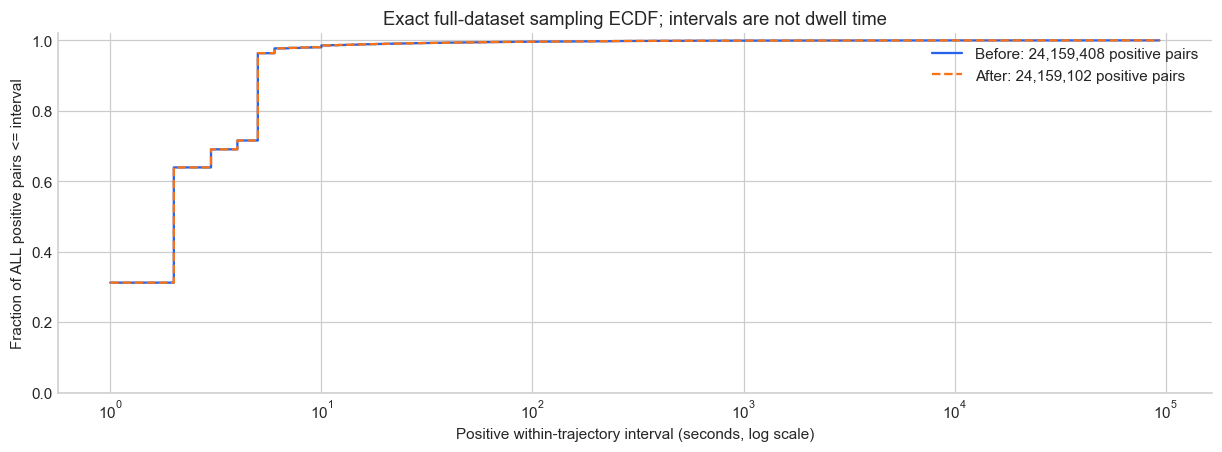

In [26]:
if report is not None:
    frequency = pd.DataFrame(report['sampling_frequency'], columns=['seconds', 'before_pairs', 'after_pairs'])
    fig, ax = plt.subplots(figsize=(11, 4), constrained_layout=True)
    for column, label, color, style in [('before_pairs', 'Before', '#2563eb', '-'), ('after_pairs', 'After', '#f97316', '--')]:
        values = frequency.loc[frequency[column] > 0].sort_values('seconds')
        n = int(values[column].sum())
        if n:
            ax.step(values.seconds, values[column].cumsum() / n, where='post', label=f'{label}: {n:,} positive pairs', color=color, linestyle=style)
    ax.set_xscale('log')
    ax.set_ylim(0, 1.02)
    ax.set_xlabel('Positive within-trajectory interval (seconds, log scale)')
    ax.set_ylabel('Fraction of ALL positive pairs <= interval')
    ax.set_title('Exact full-dataset sampling ECDF; intervals are not dwell time')
    ax.legend()
    fig.savefig(OUT / '02_sampling_before_after.png', dpi=140, bbox_inches='tight')
    plt.show()

## 9. Files kết quả và giới hạn

- `conflict_groups.csv`, `conflict_scan.json`: spread từng nhóm và chứng nhận đã scan đủ toàn dataset.
- `03_conflict_spread.png`: phân phối spread để chọn ngưỡng.
- `conflict_points.csv`: mọi conflict point sau dedup, group ID/spread/decision/ID output; nhóm xa nằm ở đây để review.
- `cleaned_points.csv.gz`: output đã gộp, flags, source_point_count và observation_segment.
- `removed_points.csv`: chỉ invalid và exact duplicates; không gọi các points đóng góp mean là bị xóa.
- `audit.json`: counts toàn dataset, chính sách spatial/context voting, ngưỡng, trạng thái và sampling frequencies.
- `01_record_counts.png`, `02_sampling_before_after.png`: so trước–sau sau khi đã chọn ngưỡng và chạy cleaning.

Mọi file ở `artifacts/preprocessing/`. Artifact cũ chưa phản ánh chính sách mới cho tới khi audit có
`conflict_policy: spatial_vote_context_v2`, `status: completed` và đủ users/files.
Khi đọc CSV dùng dtype string cho user_id/trajectory_id. Không cần load cả CSV vào RAM.

Core preprocessing nhận dữ liệu đã xử lý conflicts nên không còn được chọn fix theo lat/lon nhỏ nhất trong NB02.
CLI xử lý trực tiếp raw vẫn có rule baseline cũ; chỉ đồng bộ core/API sau khi quyết định ngưỡng/chính sách được chốt.
Trung bình không đảm bảo tọa độ thật; các nhóm vẫn chưa giải quyết và thiếu ground truth vẫn là giới hạn.

Bước stay detection tiếp theo phải tôn trọng observation_segment/segment_break_due_to_conflict; core stay detector chưa được sửa trong lượt này.